# Natural Language Processing — Lab 07
## POS Tagging & Named Entity Recognition

| | |
|---|---|
| **Student** | Eman Amjad |
| **Roll Number** | FA23-BAI-013 |
| **Course** | Natural Language Processing |

This lab uses spaCy's `en_core_web_sm` pipeline (with NLTK's tagger as a cross-check) to tag every token with its part of speech and to pull named entities out of raw text. Where the pretrained NER model misses domain terms such as product names and skill keywords, an `EntityRuler` is added in front of it to patch the gaps without retraining.

In [1]:
# Setup  |  Eman Amjad  |  FA23-BAI-013
import os
import warnings
from collections import Counter, defaultdict

import nltk
import pandas as pd
import matplotlib.pyplot as plt
import spacy
from spacy import displacy
from IPython.display import HTML, display

warnings.filterwarnings("ignore", category=FutureWarning)

# NLTK resources for the tagger comparison in Activity 1
for res in ["punkt", "punkt_tab", "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(res, quiet=True)

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 140)

# displacy.render(..., jupyter=True) imports IPython.core.display.display, which newer IPython
# releases removed; rendering to an HTML string and displaying it gives the same inline output
def show_ents(d):
    display(HTML(displacy.render(d, style="ent", jupyter=False)))

nlp = spacy.load("en_core_web_sm")
print("spaCy version :", spacy.__version__)
print("NLTK version  :", nltk.__version__)
print("Pipeline      :", nlp.pipe_names)

spaCy version : 3.8.7
NLTK version  : 3.10.4
Pipeline      : ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']


### Input data

The manual refers to a "provided news paragraph" (`news_paragraph.txt`) and a "job postings dataset" but neither file is supplied, so the cell below writes both under `data/lab07/`. The news paragraph is a short tech-news report that contains people, organisations, places, dates, money and percentages, plus the product names the activities discuss ("Pixel 10", "iPhone"). The job postings file holds ten realistic postings (company, location, skills, salary, dates) in a CSV.

In [2]:
# Data files  |  Eman Amjad  |  FA23-BAI-013
DATA_DIR = "data/lab07"  # relative, forward slashes so printed paths look the same on every OS
os.makedirs(DATA_DIR, exist_ok=True)

news_paragraph = (
    "Google announced on Tuesday that the Pixel 10 would ship to over 40 countries by October 2025. "
    "Speaking at the launch event in Mountain View, California, chief executive Sundar Pichai said the company "
    "plans to launch the phone at a starting price of $799, which is $100 less than the latest iPhone from Apple. "
    "Analysts at Counterpoint Research expect the device to capture 5 percent of the premium smartphone market "
    "in the United States within its first year. Apple shares fell 2% in New York after the announcement, while "
    "Samsung said it would reveal its own response in Seoul next month."
)
with open(os.path.join(DATA_DIR, "news_paragraph.txt"), "w", encoding="utf-8") as f:
    f.write(news_paragraph)

postings = [
    (1, "Data Analyst", "Netsol Technologies is hiring a Data Analyst for its office in Lahore. You will build weekly dashboards in Tableau, write SQL queries against our sales warehouse and present findings to the finance team. At least two years of experience with Python and Excel is required. The role offers a salary of PKR 180,000 per month and health insurance for the whole family."),
    (2, "Backend Engineer", "Careem is looking for a Backend Engineer to join its payments team in Dubai. You will design and maintain microservices written in Python and Go, deploy them on AWS, and monitor them with Grafana. Experience with Docker and Kubernetes is a strong plus. Applications close on 30 November 2025."),
    (3, "UI/UX Designer", "Systems Limited needs a UI/UX Designer in Karachi to lead the redesign of its mobile banking app. The design must be accessible and consistent across Android and iOS. You should be fluent in Figma and comfortable running usability tests with real customers. Candidates with a portfolio of three shipped products will be shortlisted first."),
    (4, "Machine Learning Engineer", "Arbisoft is hiring a Machine Learning Engineer in Islamabad. You will train and test deep learning models in PyTorch, track experiments, and ship them to production on AWS. A degree in computer science and four years of Python experience are expected. The team works a hybrid schedule with two remote days every week."),
    (5, "Frontend Developer", "Shopify is seeking a Frontend Developer based in Toronto. Your day will involve building React components, writing unit tests in Jest, and reviewing pull requests from other engineers. Knowledge of TypeScript and Figma handoff workflows is useful. The position pays between $95,000 and $120,000 a year."),
    (6, "Cloud Support Engineer", "Amazon Web Services is hiring a Cloud Support Engineer in Dublin to support enterprise customers through complex outages. You will troubleshoot networking issues on AWS, document every fix, and escalate critical incidents to the service teams. Strong Linux skills and some Python scripting are required. Shifts rotate every 12 weeks."),
    (7, "Product Manager", "Daraz is looking for a Product Manager in Lahore to lead the checkout squad. You will test new ideas with A/B experiments, write clear specifications and work closely with designers who use Figma every day. Basic SQL is needed to read your own metrics. The successful candidate will report to the Director of Product."),
    (8, "Data Engineer", "Spotify is recruiting a Data Engineer in Stockholm to build streaming pipelines with Apache Kafka and Spark. The pipelines process over 500 million events per day. You must write production Python, model tables in SQL and run jobs on Google Cloud. The team offers relocation support and a 10 percent annual bonus."),
    (9, "QA Automation Engineer", "TPS Worldwide has an opening for a QA Automation Engineer in Karachi. You will design automated test suites in Selenium and Python, run them in Jenkins, and report defects to the development team. The first round of interviews starts on 15 December 2025."),
    (10, "DevOps Engineer", "10Pearls is hiring a DevOps Engineer in Islamabad to manage infrastructure on AWS and Azure. Daily work includes writing Terraform modules, maintaining Docker images and keeping Kubernetes clusters healthy. Experience with Python or Bash scripting is required, and the support rota includes one weekend per month."),
]
pd.DataFrame(postings, columns=["posting_id", "title", "text"]).to_csv(
    os.path.join(DATA_DIR, "job_postings.csv"), index=False, encoding="utf-8")

for name in sorted(os.listdir(DATA_DIR)):
    print(f"{name:<22} {os.path.getsize(os.path.join(DATA_DIR, name)):>6} bytes")

job_postings.csv         3407 bytes
news_paragraph.txt        589 bytes
structured_postings.csv    608 bytes


---

# In-Lab Activities

**Activity 1** — Using the provided news paragraph, run spaCy's POS tagger and print each token alongside its coarse-grained `.pos_` tag and fine-grained `.tag_` tag. Identify one word in the paragraph whose tag differs from what you would expect from its most common usage.

In [3]:
# Activity 1  |  Eman Amjad  |  FA23-BAI-013
with open(os.path.join(DATA_DIR, "news_paragraph.txt"), "r", encoding="utf-8") as f:
    text = f.read()

doc = nlp(text)

print(f"{'Text':<15} | {'POS':<10} | {'TAG'}")
print("-" * 35)
for token in doc:
    print(f"{token.text:<15} | {token.pos_:<10} | {token.tag_}")

print(f"\nTotal tokens: {len(doc)}")

Text            | POS        | TAG
-----------------------------------
Google          | PROPN      | NNP
announced       | VERB       | VBD
on              | ADP        | IN
Tuesday         | PROPN      | NNP
that            | SCONJ      | IN
the             | DET        | DT
Pixel           | PROPN      | NNP
10              | NUM        | CD
would           | AUX        | MD
ship            | VERB       | VB
to              | ADP        | IN
over            | ADP        | IN
40              | NUM        | CD
countries       | NOUN       | NNS
by              | ADP        | IN
October         | PROPN      | NNP
2025            | NUM        | CD
.               | PUNCT      | .
Speaking        | VERB       | VBG
at              | ADP        | IN
the             | DET        | DT
launch          | NOUN       | NN
event           | NOUN       | NN
in              | ADP        | IN
Mountain        | PROPN      | NNP
View            | PROPN      | NNP
,               | PUNCT      | ,
Cali

In [4]:
# Activity 1 (word with an unexpected tag)  |  Eman Amjad  |  FA23-BAI-013
# 'ship' is usually a noun (a boat); here it follows the modal 'would', so the tagger reads it as a verb
for token in doc:
    if token.text in ("ship", "fell", "shares"):
        print(f"{token.text:<8} -> POS: {token.pos_:<6} TAG: {token.tag_:<4} ({spacy.explain(token.tag_)})"
              f"   context: '{doc[max(0, token.i - 3):token.i + 3].text}'")

# Same coarse tag, different fine tags: .pos_ collapses tense/agreement that .tag_ keeps
verb_tags = Counter(t.tag_ for t in doc if t.pos_ == "VERB")
print("\nFine-grained tags hidden under POS = VERB:")
for tag, n in verb_tags.most_common():
    print(f"  {tag:<4} x{n}  {spacy.explain(tag)}")

ship     -> POS: VERB   TAG: VB   (verb, base form)   context: 'Pixel 10 would ship to over'
shares   -> POS: NOUN   TAG: NNS  (noun, plural)   context: 'year. Apple shares fell 2'
fell     -> POS: VERB   TAG: VBD  (verb, past tense)   context: '. Apple shares fell 2%'

Fine-grained tags hidden under POS = VERB:
  VBD  x4  verb, past tense
  VB   x4  verb, base form
  VBG  x1  verb, gerund or present participle
  VBZ  x1  verb, 3rd person singular present
  VBP  x1  verb, non-3rd person singular present


In [5]:
# Activity 1 (cross-check with NLTK)  |  Eman Amjad  |  FA23-BAI-013
# NLTK's averaged perceptron also outputs Penn Treebank tags, so it can be compared with spaCy's .tag_
nltk_tags = nltk.pos_tag(nltk.word_tokenize(text))
spacy_tags = [(t.text, t.tag_) for t in doc]

# Both tokenizers split this paragraph the same way except around '$' and '%', so align by position only if lengths match
print(f"NLTK tokens: {len(nltk_tags)} | spaCy tokens: {len(spacy_tags)}")
if len(nltk_tags) == len(spacy_tags):
    rows = [(w, nt, st) for (w, nt), (_, st) in zip(nltk_tags, spacy_tags)]
else:
    # fall back to aligning on the shared token text in order
    rows, j = [], 0
    for w, nt in nltk_tags:
        while j < len(spacy_tags) and spacy_tags[j][0] != w:
            j += 1
        if j < len(spacy_tags):
            rows.append((w, nt, spacy_tags[j][1]))
            j += 1

agree = sum(nt == st for _, nt, st in rows)
print(f"Aligned tokens: {len(rows)} | same Penn tag: {agree} ({agree / len(rows):.1%})\n")
diff = pd.DataFrame([r for r in rows if r[1] != r[2]], columns=["token", "NLTK tag", "spaCy tag"])
print(diff.to_string(index=False))

NLTK tokens: 112 | spaCy tokens: 112
Aligned tokens: 112 | same Penn tag: 105 (93.8%)

   token NLTK tag spaCy tag
      to       TO        IN
  launch       JJ        NN
starting       JJ        NN
  iPhone       NN       NNP
 premium       JJ        NN
  States     NNPS       NNP
   Apple      NNP        NN


**Observation.** The word **"ship"** is the clearest case: its most common use is the noun (a boat), but in *"the Pixel 10 would ship to over 40 countries"* both spaCy (`VERB` / `VB`) and NLTK tag it as a base-form verb, because it follows the modal *would*. The verb summary also shows the point about granularity: tokens that all share `.pos_ = VERB` are split by `.tag_` into `VBD` (past: *announced*, *fell*), `VB` (base: *ship*, *launch*), `VBG`, `VBZ` and so on. NLTK and spaCy give the same Penn tag to 105 of the 112 tokens (93.8%). The 7 disagreements are nouns used as modifiers (*launch* event, *starting* price, *premium* market), which NLTK calls adjectives (`JJ`), proper-noun decisions (*iPhone*, *States*, and *Apple* in "Apple shares", which spaCy wrongly makes a common noun) and *to* before a noun phrase.

**Activity 2** — Find one word that appears twice in the paragraph in two different grammatical roles (for example once as a noun and once as a verb). Show both occurrences with their `.pos_` tags to demonstrate context-dependent tagging.

In [6]:
# Activity 2  |  Eman Amjad  |  FA23-BAI-013
target_word = "launch"

print(f"Context-dependent tagging for the word '{target_word}':\n")
for token in doc:
    if token.text.lower() == target_word:
        # print a small window around the token so the context is visible
        start = max(0, token.i - 2)
        end = min(len(doc), token.i + 3)
        context = doc[start:end].text
        print(f"Phrase: '... {context} ...'")
        print(f"Token: {token.text} | POS: {token.pos_} | TAG: {token.tag_} | dep: {token.dep_}\n")

Context-dependent tagging for the word 'launch':

Phrase: '... at the launch event in ...'
Token: launch | POS: NOUN | TAG: NN | dep: compound

Phrase: '... plans to launch the phone ...'
Token: launch | POS: VERB | TAG: VB | dep: xcomp



**Observation.** *"launch"* appears twice. In *"at the launch event"* it is a `NOUN` (`NN`) acting as a compound modifier of *event*; in *"plans to launch the phone"* it is a `VERB` (`VB`) after the infinitive marker *to*, with *phone* as its object. The word form is identical, so a dictionary lookup would give both the same tag; the contextual tok2vec representation is what separates them.

**Activity 3** — Process the paragraph and filter out noise tokens (`SPACE`, `PUNCT`, `X`) from the tagged output. Print a clean table of only the meaningful tokens with their POS tags.

In [7]:
# Activity 3  |  Eman Amjad  |  FA23-BAI-013
noise_tags = {"SPACE", "PUNCT", "X"}

print(f"{'Clean Text':<15} | {'POS'}")
print("-" * 25)
kept = 0
for token in doc:
    if token.pos_ not in noise_tags:
        print(f"{token.text:<15} | {token.pos_}")
        kept += 1

# The filter only changes what is printed; the Doc itself is untouched
removed = Counter(t.pos_ for t in doc if t.pos_ in noise_tags)
print(f"\nPrinted {kept} of {len(doc)} tokens; skipped {dict(removed)}")
print(f"len(doc) after filtering is still {len(doc)}")

Clean Text      | POS
-------------------------
Google          | PROPN
announced       | VERB
on              | ADP
Tuesday         | PROPN
that            | SCONJ
the             | DET
Pixel           | PROPN
10              | NUM
would           | AUX
ship            | VERB
to              | ADP
over            | ADP
40              | NUM
countries       | NOUN
by              | ADP
October         | PROPN
2025            | NUM
Speaking        | VERB
at              | ADP
the             | DET
launch          | NOUN
event           | NOUN
in              | ADP
Mountain        | PROPN
View            | PROPN
California      | PROPN
chief           | ADJ
executive       | NOUN
Sundar          | PROPN
Pichai          | PROPN
said            | VERB
the             | DET
company         | NOUN
plans           | VERB
to              | PART
launch          | VERB
the             | DET
phone           | NOUN
at              | ADP
a               | DET
starting        | NOUN
price           

**Observation.** The paragraph has no `SPACE` or `X` tokens, so only the 8 punctuation tokens are dropped and 104 of 112 tokens are printed. The `$` signs survive because spaCy tags them `SYM`, not `PUNCT`. The last line confirms the pitfall from the manual: the filter changes the printout only, and `doc` still holds all 112 tokens.

**Activity 4** — Run spaCy's NER on the paragraph and extract all entities using `doc.ents`. Visualise the entities using displaCy, and print a count of how many entities fall under each type (PERSON, ORG, GPE, DATE, MONEY, PERCENT).

In [8]:
# Activity 4  |  Eman Amjad  |  FA23-BAI-013
# Visualise entities directly in the notebook output (style="ent" = entity highlighting)
show_ents(doc)

print(f"{'Entity':<25} | {'Label':<9} | Meaning")
print("-" * 70)
for ent in doc.ents:
    print(f"{ent.text:<25} | {ent.label_:<9} | {spacy.explain(ent.label_)}")

Entity                    | Label     | Meaning
----------------------------------------------------------------------
Google                    | ORG       | Companies, agencies, institutions, etc.
Tuesday                   | DATE      | Absolute or relative dates or periods
Pixel                     | PERSON    | People, including fictional
40                        | CARDINAL  | Numerals that do not fall under another type
October 2025              | DATE      | Absolute or relative dates or periods
Mountain View             | GPE       | Countries, cities, states
California                | GPE       | Countries, cities, states
Sundar Pichai             | PERSON    | People, including fictional
799                       | MONEY     | Monetary values, including unit
100                       | MONEY     | Monetary values, including unit
Apple                     | ORG       | Companies, agencies, institutions, etc.
Counterpoint Research     | ORG       | Companies, agencies, institu

In [9]:
# Activity 4 (entity counts)  |  Eman Amjad  |  FA23-BAI-013
entity_counts = Counter([ent.label_ for ent in doc.ents])

print("Entity Type Counts (types asked for in the activity):")
print("-" * 20)
for ent_type in ["PERSON", "ORG", "GPE", "DATE", "MONEY", "PERCENT"]:
    print(f"{ent_type:<8}: {entity_counts.get(ent_type, 0)}")

others = {k: v for k, v in entity_counts.items() if k not in {"PERSON", "ORG", "GPE", "DATE", "MONEY", "PERCENT"}}
print(f"\nOther types found: {others}")
print(f"Total entities   : {len(doc.ents)}")

Entity Type Counts (types asked for in the activity):
--------------------
PERSON  : 2
ORG     : 5
GPE     : 5
DATE    : 4
MONEY   : 2
PERCENT : 2

Other types found: {'CARDINAL': 1}
Total entities   : 21


**Observation.** Most entities are correct (Google / Apple / Samsung / Counterpoint Research as ORG, Sundar Pichai as PERSON, the cities and the United States as GPE, the two prices as MONEY). There are two visible errors: **"Pixel" is tagged PERSON** (the model treats a capitalised word before a number as a first name) and the **"iPhone" is not tagged at all**. One span boundary is also wrong: the PERCENT entity swallows the verb, giving *"capture 5 percent"*. These product-name gaps are what Activity 5 fixes.

**Activity 5** — Identify one entity in the paragraph that the pretrained model misclassifies or misses entirely (e.g. a product name), add a custom `EntityRuler` pattern to capture it correctly, and verify the fix by re-running NER on the paragraph.

In [10]:
# Activity 5  |  Eman Amjad  |  FA23-BAI-013
# Baseline: what the plain model says about the product names
print("Before the ruler:")
for ent in doc.ents:
    if ent.text in ("Pixel", "Pixel 10", "iPhone") or "Pixel" in ent.text:
        print(f"  {ent.text:<12} -> {ent.label_}")
print(f"  'iPhone' tagged as an entity? {any('iPhone' in e.text for e in doc.ents)}")

# Fresh pipeline with an EntityRuler placed BEFORE the statistical ner component,
# so the rule-based spans are fixed first and ner cannot overwrite them
nlp_custom = spacy.load("en_core_web_sm")
ruler = nlp_custom.add_pipe("entity_ruler", before="ner")

patterns = [
    {"label": "PRODUCT", "pattern": "Pixel 10"},
    {"label": "PRODUCT", "pattern": "iPhone"},
]
ruler.add_patterns(patterns)
print("\nPipeline now:", nlp_custom.pipe_names)

# Re-process the text with the updated pipeline
doc_updated = nlp_custom(text)

print("\nVerified Custom Entities:")
print("-" * 25)
for ent in doc_updated.ents:
    if ent.label_ == "PRODUCT":
        print(f"Text: {ent.text:<15} | Label: {ent.label_}")

Before the ruler:
  Pixel        -> PERSON
  'iPhone' tagged as an entity? False



Pipeline now: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'entity_ruler', 'ner']

Verified Custom Entities:
-------------------------
Text: Pixel 10        | Label: PRODUCT
Text: iPhone          | Label: PRODUCT


In [11]:
# Activity 5 (before vs after)  |  Eman Amjad  |  FA23-BAI-013
show_ents(doc_updated)

before = Counter(e.label_ for e in doc.ents)
after = Counter(e.label_ for e in doc_updated.ents)
cmp = pd.DataFrame({"before": before, "after": after}).fillna(0).astype(int)
print(cmp.sort_index())

# Case sensitivity pitfall: the literal string pattern does not match a lower-case spelling
test = nlp_custom("The pixel 10 and the IPHONE were both on display.")
print("\nLower/upper-case test:", [(e.text, e.label_) for e in test.ents] or "no entities found")

          before  after
CARDINAL       1      1
DATE           4      4
GPE            5      5
MONEY          2      2
ORG            5      5
PERCENT        2      2
PERSON         2      1
PRODUCT        0      2

Lower/upper-case test: [('10', 'CARDINAL')]


**Observation.** With the ruler in front of `ner`, both **"Pixel 10"** and **"iPhone"** come out as `PRODUCT`, and the wrong PERSON label on "Pixel" is gone (PERSON drops from 2 to 1 in the comparison table). The other entities are unchanged, so the fix did not disturb what the model already got right. The last test shows the limitation from the manual: string patterns are case-sensitive, so "pixel 10" and "IPHONE" are not matched as products (only the bare number *10* is picked up, as CARDINAL).

---

# Home Activities

All home activities use the job postings file written at the top of the notebook (`data/lab07/job_postings.csv`).

In [12]:
# Home Activities (load data)  |  Eman Amjad  |  FA23-BAI-013
jobs = pd.read_csv(os.path.join(DATA_DIR, "job_postings.csv"))
print(f"Postings: {len(jobs)} | characters: {jobs.text.str.len().sum()}")
print(jobs[["posting_id", "title"]].to_string(index=False))

# nlp.pipe processes the postings as a stream, which is faster than calling nlp() in a loop
job_docs = list(nlp.pipe(jobs.text))

Postings: 10 | characters: 3143
 posting_id                     title
          1              Data Analyst
          2          Backend Engineer
          3            UI/UX Designer
          4 Machine Learning Engineer
          5        Frontend Developer
          6    Cloud Support Engineer
          7           Product Manager
          8             Data Engineer
          9    QA Automation Engineer
         10           DevOps Engineer


**Home Activity 1** — Using the job postings dataset, extract and tabulate POS tags for the full text. Report the 5 most frequent nouns and the 5 most frequent verbs across all postings combined.

POS tag distribution over all 10 postings:
  POS  count share                   meaning
 NOUN    112 19.7%                      noun
PROPN     94 16.5%               proper noun
 VERB     71 12.5%                      verb
  ADP     63 11.1%                adposition
PUNCT     53  9.3%               punctuation
  DET     39  6.9%                determiner
  AUX     30  5.3%                 auxiliary
CCONJ     28  4.9%  coordinating conjunction
  ADJ     27  4.8%                 adjective
 PRON     19  3.3%                   pronoun
  NUM     17  3.0%                   numeral
 PART      7  1.2%                  particle
  SYM      4  0.7%                    symbol
  ADV      3  0.5%                    adverb
SCONJ      1  0.2% subordinating conjunction


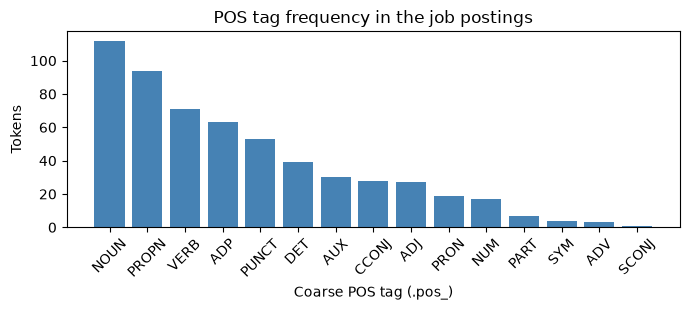

In [13]:
# Home Activity 1  |  Eman Amjad  |  FA23-BAI-013
pos_counts = Counter(t.pos_ for d in job_docs for t in d)
pos_table = (pd.DataFrame(pos_counts.items(), columns=["POS", "count"])
             .sort_values("count", ascending=False).reset_index(drop=True))
pos_table["share"] = (pos_table["count"] / pos_table["count"].sum()).map("{:.1%}".format)
pos_table["meaning"] = pos_table["POS"].map(spacy.explain)
print("POS tag distribution over all 10 postings:")
print(pos_table.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(pos_table["POS"], pos_table["count"], color="steelblue")
ax.set_title("POS tag frequency in the job postings")
ax.set_xlabel("Coarse POS tag (.pos_)")
ax.set_ylabel("Tokens")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [14]:
# Home Activity 1 (top nouns and verbs)  |  Eman Amjad  |  FA23-BAI-013
# Lemmas merge 'tests'/'test' and 'writing'/'write', so the counts reflect the word, not the inflection
nouns = Counter(t.lemma_.lower() for d in job_docs for t in d if t.pos_ == "NOUN")
verbs = Counter(t.lemma_.lower() for d in job_docs for t in d if t.pos_ == "VERB")

top = pd.DataFrame({
    "noun": [w for w, _ in nouns.most_common(5)],
    "noun_count": [c for _, c in nouns.most_common(5)],
    "verb": [w for w, _ in verbs.most_common(5)],
    "verb_count": [c for _, c in verbs.most_common(5)],
}, index=range(1, 6))
print(top)

# Penn tags tabulated for the nouns/verbs, to show the fine-grained split
fine = Counter(t.tag_ for d in job_docs for t in d if t.pos_ in ("NOUN", "VERB"))
print("\nFine-grained tags behind NOUN/VERB:", dict(fine.most_common()))

         noun  noun_count     verb  verb_count
1        team           6    write           6
2  experience           4     hire           4
3         day           4    build           3
4        year           3  require           3
5        test           3      run           3

Fine-grained tags behind NOUN/VERB: {'NN': 68, 'NNS': 44, 'VB': 30, 'VBG': 17, 'VBZ': 11, 'VBN': 10, 'VBP': 3}


**Observation.** The most frequent nouns (*team*, *experience*, *day*, *year*, *test*) and verbs (*write*, *hire*, *build*, *require*, *run*) read like a summary of a job advert: who you work with, how much experience is needed, and what you will actually do day to day. Proper nouns such as company and tool names are tagged `PROPN`, not `NOUN`, so they do not crowd this list.

**Home Activity 2** — On the same dataset, extract named entities with spaCy's NER, group them by entity type, and report the count for each type. Note which type appears most often and why that makes sense for job postings.

In [15]:
# Home Activity 2  |  Eman Amjad  |  FA23-BAI-013
by_type = defaultdict(list)
for pid, d in zip(jobs.posting_id, job_docs):
    for ent in d.ents:
        by_type[ent.label_].append(ent.text)

summary = pd.DataFrame(
    [(label, len(texts), ", ".join(sorted(set(texts)))) for label, texts in by_type.items()],
    columns=["type", "count", "distinct entities"],
).sort_values("count", ascending=False).reset_index(drop=True)
print(summary.to_string(index=False, max_colwidth=90))
print(f"\nTotal entities: {summary['count'].sum()} | most frequent type: {summary.iloc[0]['type']}")

# One posting rendered to see the errors in place
show_ents(job_docs[1])

       type  count                                                                          distinct entities
        ORG     26 AWS, Amazon Web Services, Android, Backend Engineer, Data, Figma, Kubernetes, PKR 180,0...
        GPE     15 Dubai, Dublin, Islamabad, Jenkins, Jest, Karachi, Lahore, Python, React, Stockholm, Tab...
     PERSON      9          10Pearls, Bash, Daraz, Docker, Grafana, Netsol Technologies, Python, Strong Linux
       DATE      9 15 December 2025, 30 November 2025, At least two years, annual, every 12 weeks, four ye...
   CARDINAL      2                                                                    over 500 million, three
    ORDINAL      2                                                                                      first
WORK_OF_ART      2                                                Cloud Support Engineer, Selenium and Python
    PRODUCT      2                                                                 Apache Kafka, Google Cloud
      MONE

**Observation.** **ORG** is the most frequent type, followed by **GPE**. That fits job postings: every posting names the hiring company and a city, and tech postings are full of other organisation-like proper nouns (cloud vendors, frameworks). Part of the ORG count is inflated by errors, though: tools such as *SQL*, *AWS*, *Kubernetes* and *Figma* are labelled ORG, while *Python*, *Tableau*, *React* and *Jest* end up as GPE or PERSON, and some real companies (*Netsol Technologies*, *Daraz*, *10Pearls*) are labelled PERSON. The model has no notion of a "skill", which is the gap the next activity patches.

**Home Activity 3** — Pick one skill term that spaCy's default model does not tag correctly, add a custom `EntityRuler` pattern for it, and verify it is now extracted across all postings.

In [16]:
# Home Activity 3  |  Eman Amjad  |  FA23-BAI-013
SKILL_TERM = "Python"

def python_labels(d):
    """Labels the given pipeline assigns to each mention of the skill term."""
    out = []
    for t in d:
        if t.text == SKILL_TERM:
            out.append(t.ent_type_ or "(none)")
    return out

before = [python_labels(d) for d in job_docs]

nlp_skill = spacy.load("en_core_web_sm")
skill_ruler = nlp_skill.add_pipe("entity_ruler", before="ner")
skill_ruler.add_patterns([{"label": "SKILL", "pattern": SKILL_TERM}])
skill_docs = list(nlp_skill.pipe(jobs.text))
after = [[e.label_ for e in d.ents if e.text == SKILL_TERM] for d in skill_docs]

check = pd.DataFrame({
    "posting_id": jobs.posting_id,
    "mentions": [d.text.count(SKILL_TERM) for d in job_docs],
    "default model": [", ".join(b) or "-" for b in before],
    "with ruler": [", ".join(a) or "-" for a in after],
})
print(check.to_string(index=False))

n_mentions = check["mentions"].sum()
n_fixed = sum(len(a) for a in after)
print(f"\n'{SKILL_TERM}' mentions: {n_mentions} | extracted as SKILL with the ruler: {n_fixed}")

 posting_id  mentions default model with ruler
          1         1           ORG      SKILL
          2         1           GPE      SKILL
          3         0             -          -
          4         1        (none)      SKILL
          5         0             -          -
          6         1           ORG      SKILL
          7         0             -          -
          8         1        (none)      SKILL
          9         1   WORK_OF_ART      SKILL
         10         1        PERSON      SKILL

'Python' mentions: 7 | extracted as SKILL with the ruler: 7


**Observation.** Without help, the default model labels *Python* inconsistently: across its 7 mentions it comes out as ORG twice (once inside the wrong span "Python and Excel"), GPE once, PERSON once, WORK_OF_ART once (inside "Selenium and Python"), and twice it is not tagged at all. After adding a single `{"label": "SKILL", "pattern": "Python"}` rule before `ner`, every mention in every posting is extracted as `SKILL`, which the table confirms row by row.

**Home Activity 4** — Find one word in the job postings whose POS tag changes across postings depending on context (e.g. noun in one posting, verb in another). Show both occurrences with their tags.

In [17]:
# Home Activity 4  |  Eman Amjad  |  FA23-BAI-013
# Search for lemmas that appear as both NOUN and VERB somewhere in the dataset
roles = defaultdict(set)
for d in job_docs:
    for t in d:
        if t.pos_ in ("NOUN", "VERB"):
            roles[t.lemma_.lower()].add(t.pos_)
both = sorted(w for w, r in roles.items() if r == {"NOUN", "VERB"})
print("Lemmas tagged both NOUN and VERB:", both)

target = "design"
print(f"\nEvery occurrence of '{target}':")
for pid, d in zip(jobs.posting_id, job_docs):
    for t in d:
        if t.text.lower() == target:
            ctx = d[max(0, t.i - 3):t.i + 4].text
            print(f"  posting {pid:>2} | {t.pos_:<5} {t.tag_:<4} | '... {ctx} ...'")

Lemmas tagged both NOUN and VERB: ['design', 'support', 'test', 'work']

Every occurrence of 'design':
  posting  2 | VERB  VB   | '... . You will design and maintain microservices ...'
  posting  3 | NOUN  NN   | '... app. The design must be accessible ...'
  posting  9 | VERB  VB   | '... . You will design automated test suites ...'


**Observation.** *"design"* is a verb in postings 2 and 9 (*"You will design and maintain microservices"*, *"You will design automated test suites"*, after the modal *will*) and a noun in posting 3 (*"The design must be accessible"*, after the determiner *the*). The search also turns up other words with the same behaviour in this dataset (for example *test* and *support*), which is common in job adverts where tasks are described both as actions and as things.

**Home Activity 5** — Build a simple structured extractor: for each posting, use NER plus the custom `EntityRuler` from Home Activity 3 to pull out the company (ORG), location (GPE) and skill keywords into a clean row-per-posting table (posting id, company, location, skills found).

In [18]:
# Home Activity 5 (naive extractor)  |  Eman Amjad  |  FA23-BAI-013
def first_label(d, label):
    return next((e.text for e in d.ents if e.label_ == label), None)

# First attempt: only the Python rule from Home Activity 3 on top of the plain model
naive = pd.DataFrame({
    "posting_id": jobs.posting_id,
    "company": [first_label(d, "ORG") for d in skill_docs],
    "location": [first_label(d, "GPE") for d in skill_docs],
    "skills": [", ".join(sorted({e.text for e in d.ents if e.label_ == "SKILL"})) for d in skill_docs],
})
print(naive.to_string(index=False))

 posting_id             company  location skills
          1                Data    Lahore Python
          2    Backend Engineer     Dubai Python
          3                  UI   Karachi       
          4             PyTorch Islamabad Python
          5          TypeScript   Toronto       
          6 Amazon Web Services    Dublin Python
          7               Figma    Lahore       
          8             Spotify Stockholm Python
          9       TPS Worldwide   Karachi Python
         10                 AWS Islamabad Python


The naive table already shows why the rule layer matters: with only the *Python* rule, "company" picks up fragments of job titles and tool names (*Data*, *Backend Engineer*, *UI*, *PyTorch*, *TypeScript*, *Figma*, *AWS*) and is right for only 3 of 10 postings, and the skills column only ever contains Python. The extractor below extends the same ruler with the full skill vocabulary and the posting titles, so neither can be mistaken for a company, and restricts the company to the opening sentence, which is where every posting names its employer.

In [19]:
# Home Activity 5 (structured extractor)  |  Eman Amjad  |  FA23-BAI-013
SKILLS = ["Python", "SQL", "Excel", "Tableau", "Go", "AWS", "Azure", "Google Cloud", "Grafana",
          "Docker", "Kubernetes", "Figma", "PyTorch", "React", "Jest", "TypeScript", "Linux",
          "Apache Kafka", "Spark", "Selenium", "Jenkins", "Terraform", "Bash"]

nlp_ext = spacy.load("en_core_web_sm")
ext_ruler = nlp_ext.add_pipe("entity_ruler", before="ner")
patterns = [{"label": "SKILL", "pattern": s} for s in SKILLS]
# Job titles are already known from the dataset's title column; tagging them stops ner calling them ORG
patterns += [{"label": "JOB_TITLE", "pattern": t} for t in jobs.title.unique()]
ext_ruler.add_patterns(patterns)

def extract(pid, d):
    first_sent = next(d.sents)
    # company: an ORG in the opening sentence; if ner gave none (or mislabelled it),
    # fall back to the grammatical subject of that sentence
    company = next((e.text for e in first_sent.ents if e.label_ == "ORG"), None)
    source = "NER (ORG)"
    if company is None:
        subj = next((t for t in first_sent if t.dep_ == "nsubj"), None)
        if subj is not None:
            company = d[subj.left_edge.i:subj.i + 1].text
            source = "parse (subject)"
    location = next((e.text for e in d.ents if e.label_ == "GPE"), None)
    skills = sorted({e.text for e in d.ents if e.label_ == "SKILL"})
    return {"posting_id": pid, "company": company, "company_source": source,
            "location": location, "skills_found": ", ".join(skills), "n_skills": len(skills)}

ext_docs = list(nlp_ext.pipe(jobs.text))
table = pd.DataFrame([extract(pid, d) for pid, d in zip(jobs.posting_id, ext_docs)])
print(table.to_string(index=False))

 posting_id             company  company_source  location                                            skills_found  n_skills
          1 Netsol Technologies parse (subject)    Lahore                             Excel, Python, SQL, Tableau         4
          2              Careem parse (subject)     Dubai            AWS, Docker, Go, Grafana, Kubernetes, Python         6
          3     Systems Limited parse (subject)   Karachi                                                   Figma         1
          4            Arbisoft parse (subject) Islamabad                                    AWS, PyTorch, Python         3
          5             Shopify parse (subject)   Toronto                          Figma, Jest, React, TypeScript         4
          6 Amazon Web Services       NER (ORG)    Dublin                                      AWS, Linux, Python         3
          7               Daraz parse (subject)    Lahore                                              Figma, SQL         2
        

In [20]:
# Home Activity 5 (check and export)  |  Eman Amjad  |  FA23-BAI-013
# Hand-checked companies/locations, used only to score the two extractors
gold_company = ["Netsol Technologies", "Careem", "Systems Limited", "Arbisoft", "Shopify",
                "Amazon Web Services", "Daraz", "Spotify", "TPS Worldwide", "10Pearls"]
gold_location = ["Lahore", "Dubai", "Karachi", "Islamabad", "Toronto",
                 "Dublin", "Lahore", "Stockholm", "Karachi", "Islamabad"]

for name, df, skill_col in [("naive", naive, "skills"), ("structured", table, "skills_found")]:
    c = (df["company"] == pd.Series(gold_company)).sum()
    l = (df["location"] == pd.Series(gold_location)).sum()
    n_sk = df[skill_col].map(lambda s: len(s.split(", ")) if s else 0).sum()
    print(f"{name:<11} company correct: {c}/10 | location correct: {l}/10 | skill mentions extracted: {n_sk}")

out_path = f"{DATA_DIR}/structured_postings.csv"
table.drop(columns=["company_source"]).to_csv(out_path, index=False)
print(f"\nSaved {len(table)} rows to {out_path}")

naive       company correct: 3/10 | location correct: 10/10 | skill mentions extracted: 7
structured  company correct: 10/10 | location correct: 10/10 | skill mentions extracted: 38

Saved 10 rows to data/lab07/structured_postings.csv


**Observation.** Against the hand-checked values, the naive extractor gets the company right for 3/10 postings and the structured one for 10/10; location is 10/10 for both, because the first GPE in each posting is the city. Skill extraction goes from 7 mentions (Python only) to 38. Company is the hard field: the statistical model mislabels several employer names as PERSON (*Netsol Technologies*, *Daraz*, *10Pearls*) or misses them (*Careem*, *Systems Limited*, *Shopify*, *Arbisoft*), so 7 of the 10 rows came from the subject-of-first-sentence fallback, as the `company_source` column shows. That heuristic works here because every posting opens with "<Company> is hiring / is looking for ..."; on postings written differently it would need more rules. Skills come entirely from the rule layer, which is the realistic recruiting-automation pattern: a pretrained model for general entities plus a maintained vocabulary of domain terms, with the result saved as a clean table (`data/lab07/structured_postings.csv`) ready to load into a database.

---

### Lab 07 complete

5 in-lab activities and 5 home activities — submitted by Eman Amjad (FA23-BAI-013).